# Fish Stories

In [11]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Circle, Polygon

I have this vision of a water scene where you can upload/select pictures of fish and kelp and stuff, and they swim around.
The idea isn't so complicated. I want the fish to be something like this I guess:

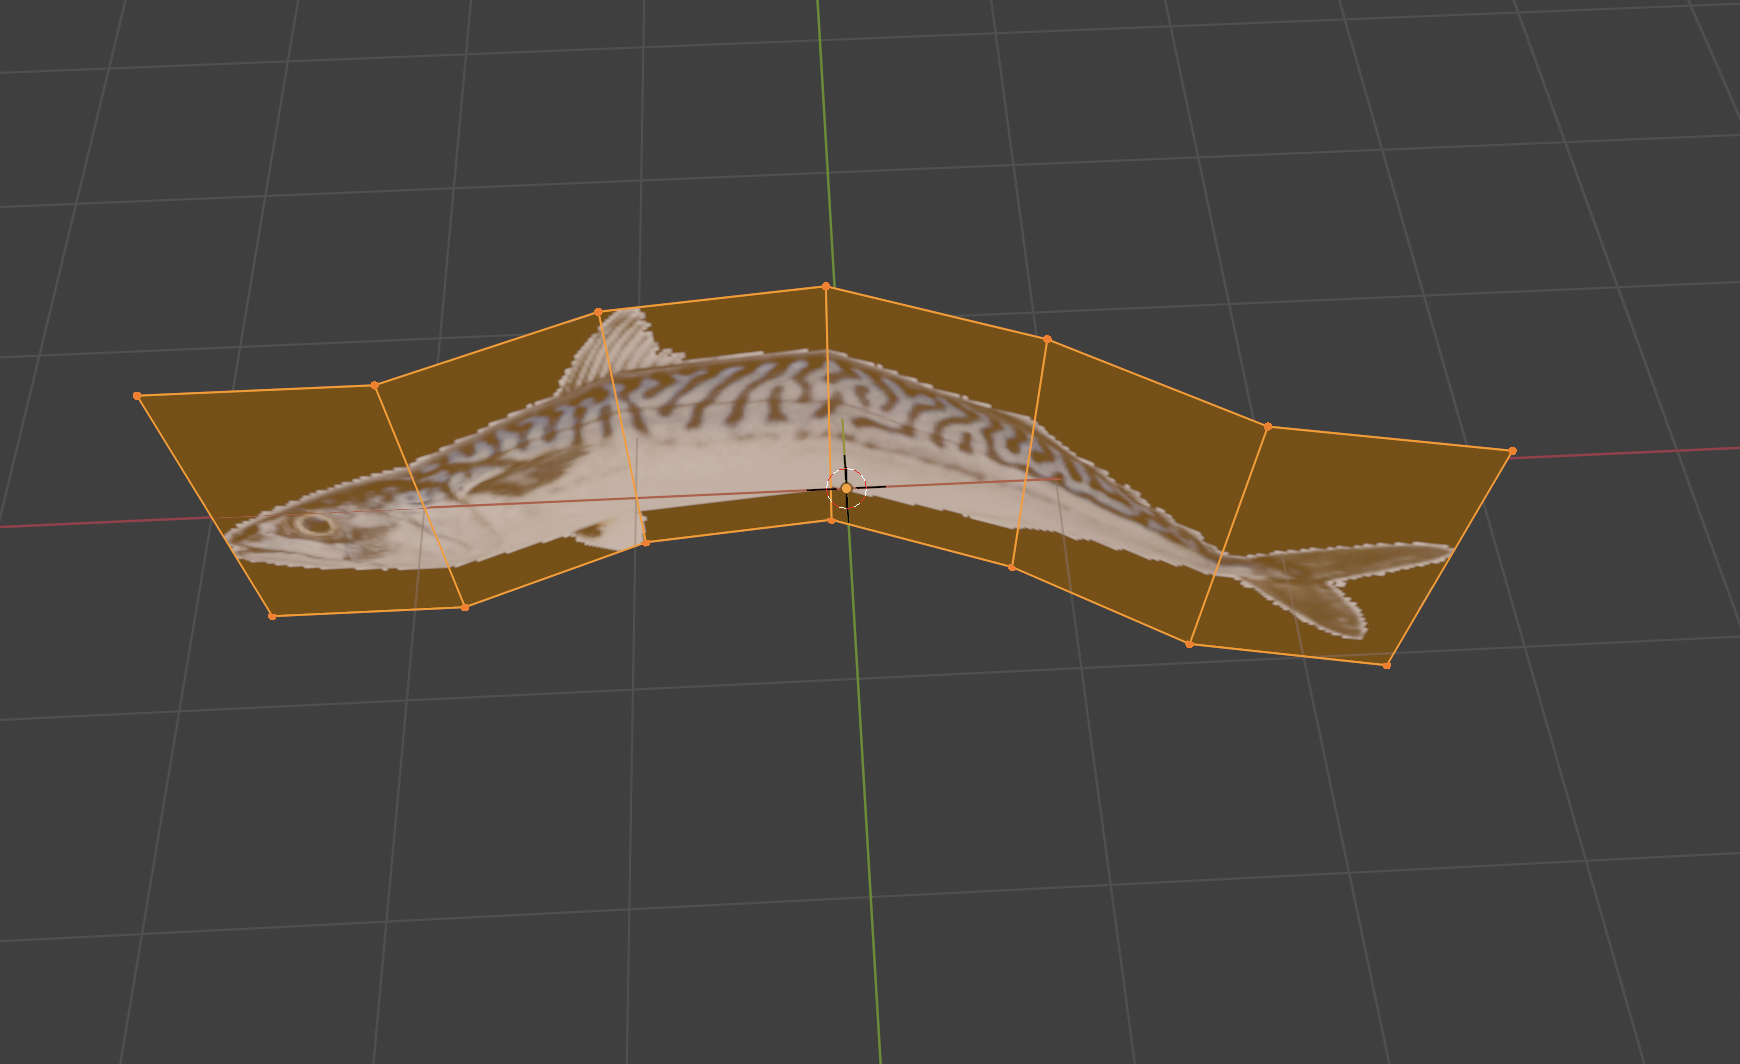

So now, if we know how we want the fish to move, how do we orient the planes against each other? 🤔

Let's formulate the problem correctly.

Let's say we know how long we want the fish to be and how many segments it needs. So we have $n$ segments each with length $q$. And looking straight down at the fish, each part really is just a line segment. This makes our formulation a bit easier.

So say we can describe the motion of the fish with some function
$$M(x,t)$$
where $t$ is time and $x$ is the distance along the axis (Cranial -> Caudal, so head is 0).

We then realize that we have these "discrete" line segments each with fixed length $q$, and we want a sequence of points
$$p_1(t), p_2(t), ..., p_n(t), \quad p_i(t) = \big(x_i(t),\ y_i(t)\big)$$
where
$$y_i(t) = M(x_i(t),\ t)$$
and for $2 \leq i \leq n$
$$L2(p_i(t),\ p_{i-1}(t)) = q$$

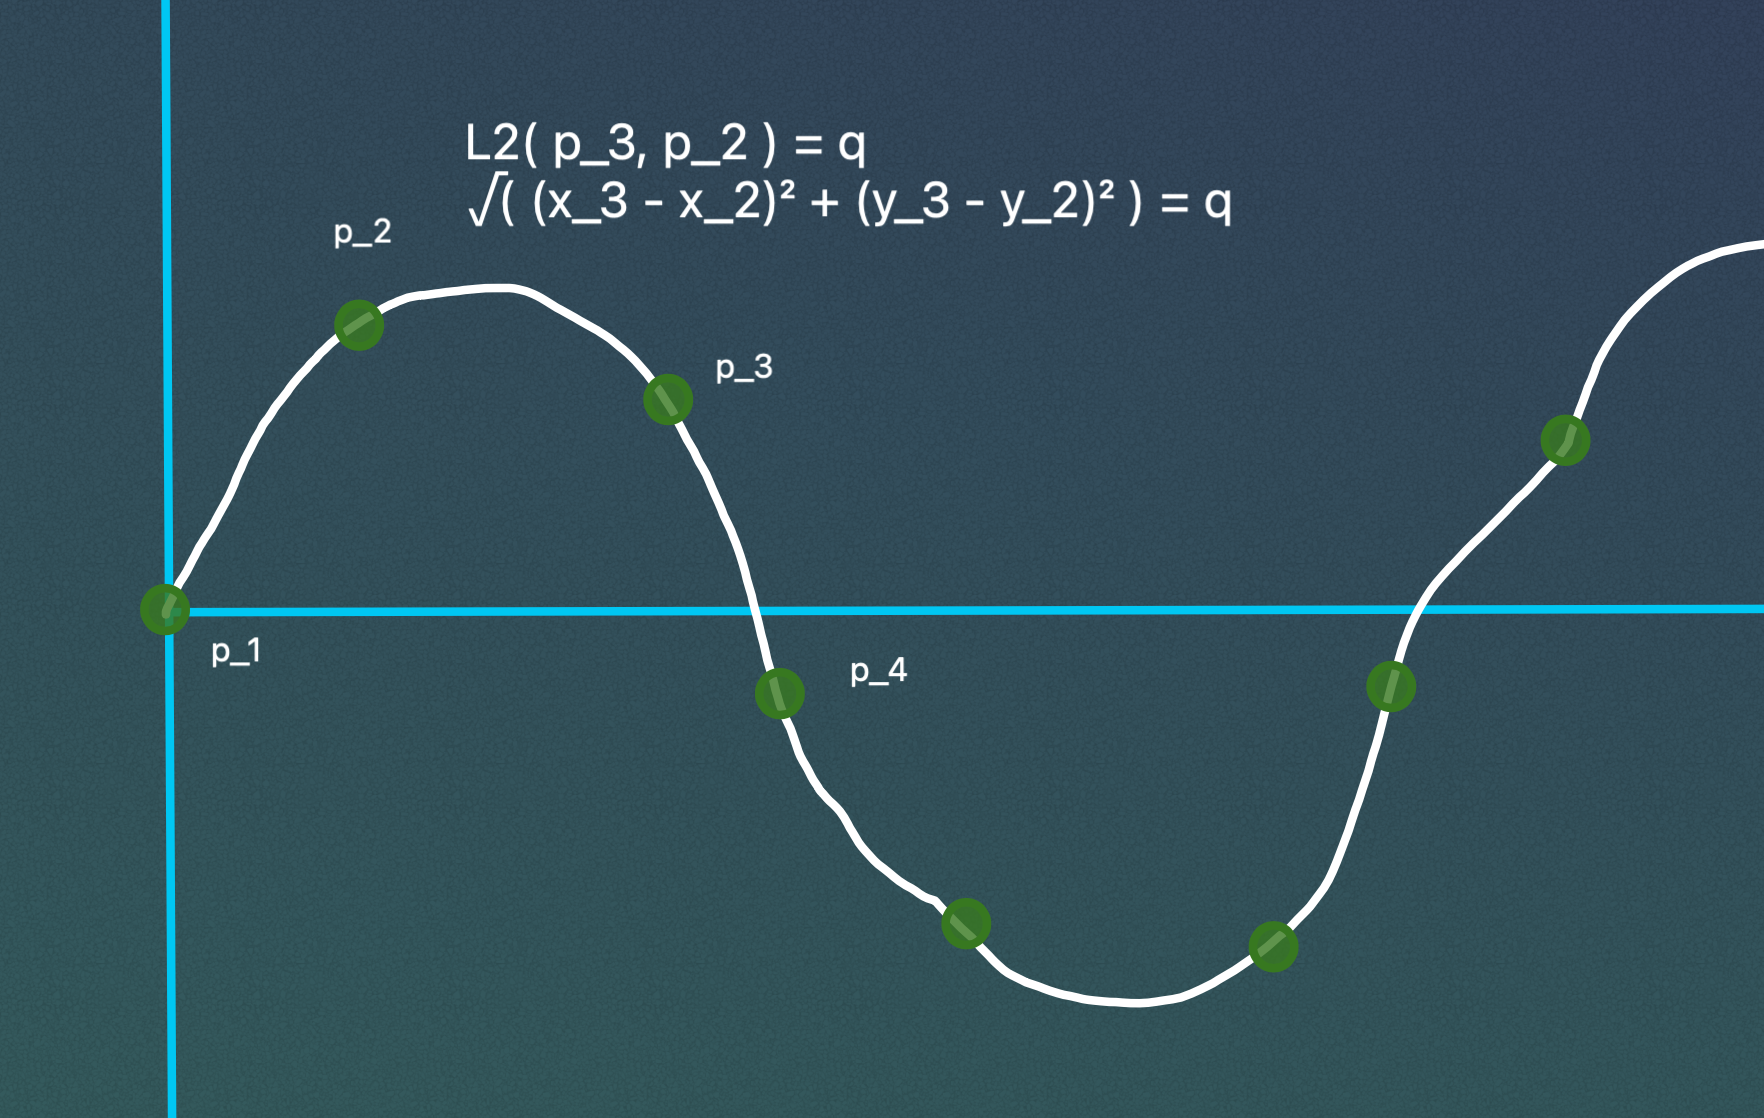

This problem is weird because I'm looking for the points to be equidistant, instead of sampling the x axis regularly. I'm 100% sure someone has solved this already. But I don't know what to call it so I can't google it. Whatever let's see where the rabbit hole goes.

I want a lot of fish too so this has gotta be cheap or parallelizable.

# Attempt 1: Precision Search

We want $q$ to be less than $\frac{\pi}{4}$ so that the points don't alias. Just based on vibes I think at this scale the L2 distance is monotonically increasing, so maybe we can binary search up to some precision (e.g. $\varepsilon = 0.001$ or something). Let's find out

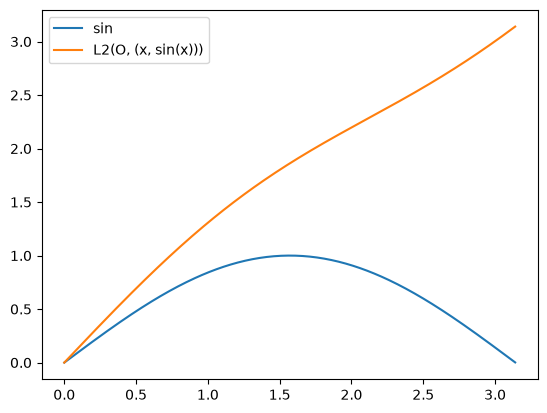

In [2]:
xs = []
ys = []
ds = []


for c in np.arange(0, np.pi, 0.01):
    xs.append(c)
    ys.append(np.sin(c))
    ds.append(np.hypot(c, np.sin(c)))

plt.plot(xs, ys, label="sin")
plt.plot(xs, ds, label="L2(O, (x, sin(x)))")
plt.legend()
plt.show()

Nice. looks ok. Let's try a few offsets to make sure

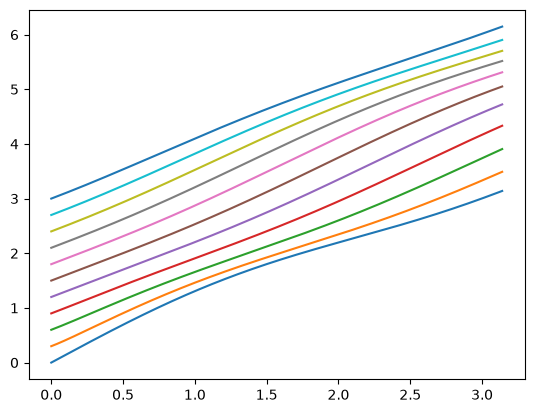

In [3]:
OFFSET_DELTA = 0.3
d2s_stagger = [[] for _ in np.arange(0, np.pi, OFFSET_DELTA)]
d2s = [[] for _ in np.arange(0, np.pi, OFFSET_DELTA)]

for c in np.arange(0, np.pi, 0.01):
    for idx, o in enumerate(np.arange(0, np.pi, OFFSET_DELTA)):
        d2s_stagger[idx].append(np.hypot(c + o, np.sin(c + o) - np.sin(o)))
        d2s[idx].append(np.hypot(c, np.sin(c + o) - np.sin(o)))

for idx, o in enumerate(np.arange(0, np.pi, OFFSET_DELTA)):
    plt.plot(xs, d2s_stagger[idx])
plt.show()

I'm convinced. Here's a further hypothesis: For a set value of $q$, we can find bounds to shrink our search.

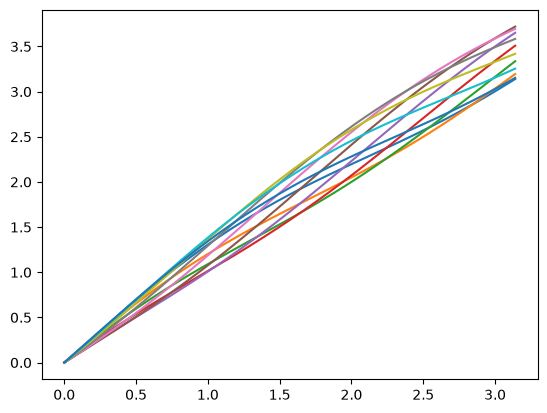

In [4]:
for idx, o in enumerate(np.arange(0, np.pi, OFFSET_DELTA)):
    plt.plot(xs, d2s[idx])
plt.show()

# Aside: Fish Motion

Wait a sec. Fish don't move in sine waves. How do fish move? This is for sure solved since people make robotic fish

- https://www.mdpi.com/2076-3417/14/8/3239
- 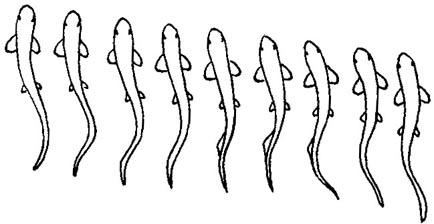
- https://www.sciencedirect.com/science/article/abs/pii/S016521251830009X

Basically a travelling sine wave (WRT the fish) and the amplitude increases from head to tail. Importantly the amplitude at the head is not zero, but it is smaller.

I think this tells us that any "elementary" solution e.g. using arclength or something, which I investigated, would not work because the profile of the function changes with time and distance. Since this changes the aspect ratio between x and y, I think it must be computed numerically.

## Approach 2: Iterative Search

So now we reduce the problem, instead of finding $p_i$ given $i$, we just find $p_i$ given $p_{(i-1)}$.

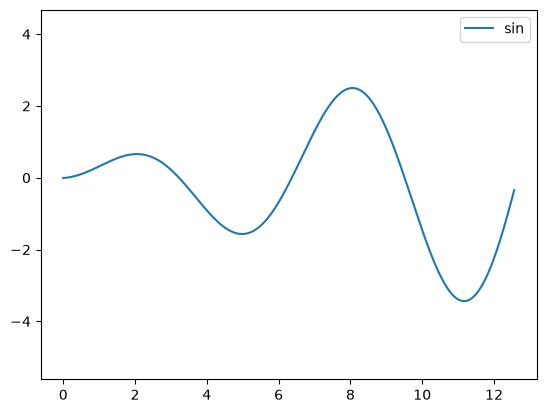

In [20]:
xs = []
ys = []

def csin(x, t):
    return (x * 0.3 + 0.1) * np.sin(x - t / 12)

fig, ax = plt.subplots()

plt.axis('equal')

xs = np.arange(0, 4 * np.pi, 0.01)
plt.plot(xs, csin(xs, 1), label="sin")

plt.legend()
plt.show()

In [39]:
eps = 0.1
def next_pt(x, y, t, q):
    l = q * 0.5
    r = q
    iters = 0
    mid_dist = 0
    while(r - l > eps):
        iters += 1
        mid = (l + r) / 2
        mid_y = csin(x + mid, t)

        mid_dist = np.hypot(mid, mid_y - y)

        if(mid_dist > q):
            r = mid
        else:
            l = mid

    mid = (l + r) / 2
    mid_y = csin(x + mid, t)

    print("after ({},{}) is point ({}, {}) with distance {} (in {} iters)".format(x, y, mid, mid_y, mid_dist, iters))

    return (x + mid, mid_y)

after (0,-0.0995407957751765) is point (1.259375, -0.1892729988518671) with distance 1.223020548781636 (in 3 iters)
after (1.259375,-0.1892729988518671) is point (1.0968750000000003, 0.5133466030255254) with distance 1.2505831980283508 (in 3 iters)
after (2.35625,0.5133466030255254) is point (1.178125, 1.109542443206136) with distance 1.3553568549375268 (in 3 iters)
after (3.5343750000000003,1.109542443206136) is point (1.015625, 0.3741580521413296) with distance 1.3193531782248136 (in 3 iters)
after (4.550000000000001,0.3741580521413296) is point (0.690625, -0.7006799323214029) with distance 1.355615886931723 (in 3 iters)


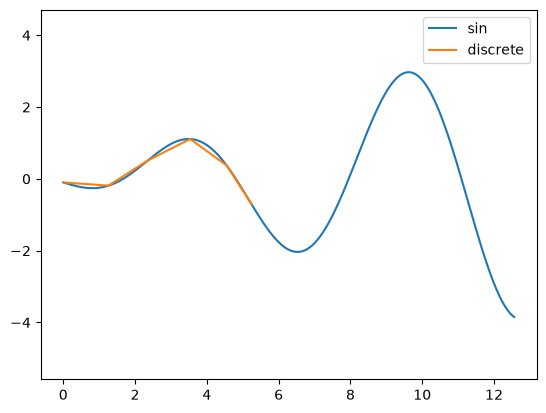

In [40]:
q = 1.3
t = 20

fig, ax = plt.subplots()

plt.axis('equal')
plt.plot(xs, csin(xs, t), label="sin")

# start from zero
verts = []
vys = []


verts.append(0)
vys.append(csin(0, t))

for i in range(5):
    lastx = verts[-1]
    lasty = vys[-1]
    nx, ny = next_pt(lastx, lasty, t, q)

    verts.append(nx)
    vys.append(ny)

    # ax.add_patch(Circle((nx, ny), radius=q, edgecolor='lightcoral', facecolor='none'))

plt.plot(verts, vys, label="discrete")

plt.legend()
plt.show()

wait shit that looks good